# GroupMemory: a small, reproducible QML classifier

Install the package with `python -m pip install -e ".[dev]"` from the repository root, select that Python environment, then **Run All**. This notebook generates synthetic data and runs on your CPU. It requires no QPU, account, model download or remote compute. Expected runtime: seconds to a few minutes.

We compare a dictionary-based symmetry cache, Qiskit supplied the same symmetry, Qiskit with exact-input caching, and a strong classical model. The symmetry is known for the fixed ring architecture. There is no claim of quantum advantage or arbitrary-circuit symmetry discovery. The cache stores classical results, not quantum states.

There are four independent histogram pairs per split (eight base patterns), each expanded into four related views. The views are not independent test examples. Two shared quantum weights receive three updates; the classical head is refitted between updates.

In [1]:
import os
for name in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"]:
    os.environ.setdefault(name, "1")
import numpy as np
import matplotlib.pyplot as plt
from threadpoolctl import threadpool_limits
from group_memory_qml.data import make_sensor_dataset, four_views
from group_memory_qml.engine import QMLReuseEngine
from group_memory_qml.training import METHODS, run_trial, validate_matched_block


## Four related requests, one computation

A rotation or reflection of the sensor ring permutes local-Z outputs. Their mean and its shared-weight gradient are invariant. The wrapper selects an exact representative, evaluates it once and restores the original output ordering.

In [2]:
data = make_sensor_dataset(6, 846101)
x = data.test_x[0]
views = four_views(x)
with threadpool_limits(limits=1):
    engine = QMLReuseEngine(6)
    z, gradient = engine.evaluate(views, [.53, -.41], gradient=True)
print({"requested_views": len(views), "forward_states": engine.forward_count,
       "classical_gradient_instances": engine.gradient_count})
print("Mean Z for the four equivalent views:", z.mean(axis=1))
np.testing.assert_allclose(z.mean(axis=1), z.mean(axis=1)[0], atol=1e-10, rtol=0)
assert engine.forward_count == engine.gradient_count == 1


{'requested_views': 4, 'forward_states': 1, 'classical_gradient_instances': 1}
Mean Z for the four equivalent views: [0.38527405 0.38527405 0.38527405 0.38527405]


## Train and compare all four methods

This walkthrough uses one fixed order and one seed for clarity. Use the CLI for randomized matched order, multiple seeds, saved raw results and full-run overhead accounting. The application timer includes data preparation, compilation, canonicalization, simulation, gradients and classical fitting. Notebook startup, validation and plotting are outside these per-application values.

In [3]:
with threadpool_limits(limits=1):
    records = [run_trial(n_qubits=6, seed=846101, method=method, updates=3) for method in METHODS]
check = validate_matched_block(records)
print(check)
for record in records:
    print(f"{record['method']:24s} accuracy={record['heldout_accuracy']:.2%} "
          f"application={record['pipeline_s']:.4f}s "
          f"forward={record['forward_evaluations']} "
          f"gradient_instances={record['gradient_instances']}")


{'status': 'PASS', 'max_prediction_error': 3.9968028886505635e-15, 'max_partial_gradient_error': 3.4416913763379853e-15}
group_memory             accuracy=75.00% application=0.3668s forward=40 gradient_instances=24
qiskit_same_symmetry     accuracy=75.00% application=0.3090s forward=40 gradient_instances=24
qiskit_exact_cache       accuracy=75.00% application=1.2292s forward=160 gradient_instances=96
classical                accuracy=100.00% application=0.0035s forward=0 gradient_instances=0


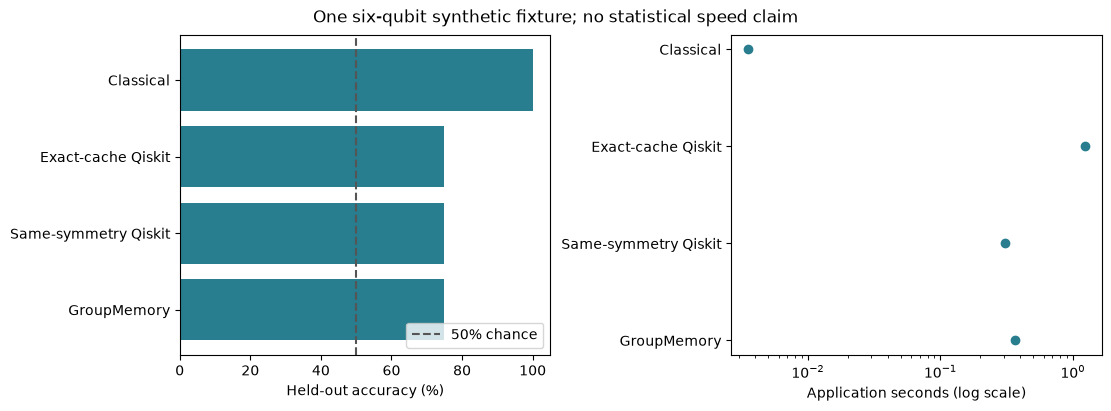

In [4]:
labels = ["GroupMemory", "Same-symmetry Qiskit", "Exact-cache Qiskit", "Classical"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
axes[0].barh(labels, [r['heldout_accuracy'] * 100 for r in records], color="#287d8e")
axes[0].set_xlim(0, 105)
axes[0].axvline(50, color="#555555", linestyle="--", label="50% chance")
axes[0].set_xlabel("Held-out accuracy (%)"); axes[0].legend(loc="lower right")
axes[1].scatter([r['pipeline_s'] for r in records], labels, color="#287d8e")
axes[1].set_xscale("log"); axes[1].set_xlabel("Application seconds (log scale)")
fig.suptitle("One six-qubit synthetic fixture; no statistical speed claim")
plt.show()


## Cache validity and interpretation

Changing a weight invalidates the cache; shared gate structure alone does not justify reusing old predictions or gradients. Supplying `symmetry=False` constructs site-dependent gains and disables orbit reuse. Both behaviors have regression tests.

The same-symmetry baseline can obtain the same mathematical reduction. The classical model may be faster and more accurate. Avoided forward CNOT work counts fewer executed circuits, not fewer CNOTs inside each circuit. Reverse-mode derivatives here are classical CPU computations, not quantum gradient jobs.

For a fuller comparison run:

```bash
python -m group_memory_qml.demo --qubits 10 --seeds 846101 846102 846103 --repeats 2 --output results/my-run
```

Reports should include misses, overhead, above-chance accuracy and the strongest baseline—not only the number of cache hits.